# Music Genre Classification from Mel Spectrograms

**DATASCI 207 - Section 5, Group 3**

Caroline Nealon · Cyrus Tabatabai · Hussain Zaidi · Matthew Thomas

**Repo:** https://github.com/cyrustaba/datasci-207-final-project

---

**Dataset:** FMA-small (https://github.com/mdeff/fma)

**Input:** mel spectrogram - `(128, 1292)` float32 full resolution, pooled to `(128, 128)`
float16 for modeling (Section 3.5)

**Target:** `genre_top` - 8 classes · **Chance accuracy:** 12.5%

**Splits after preprocessing:** train 6,393 · validation 800 · test 800
(7 tracks dropped: 6 conversion failures + 1 silent track)

---

### Running this notebook

Paths are relative (`../data/local/`), so run from a `notebooks/` directory. Large files
live in `data/local/` (git-ignored); small derived files in `data/tracked/` (committed).

Section 2.0 detects what is available and sets `RELOADED`, `HAVE_NPY`, `HAVE_AUDIO` and
`HAVE_METADATA`. Cells that need raw audio, FMA metadata, or the full `.npy` cache are
guarded and print a skip message rather than failing, so the notebook runs end to end in
any of three setups:

| Setup | Needs | Sections that run |
|---|---|---|
| **Full build** | MP3s + `tracks.csv` | everything |
| **Cached** | the four CSVs + `processed_mel/*.npy` | everything except 2.1-2.4 |
| **Compact only** | the four CSVs + `mel_compact.npz` (~200 MB) | 3.5 onward - all modeling |

Run `Kernel → Restart & Run All` before every commit so cell numbering starts at 1.

---
## <span style="color: chocolate;">1 · Setup</span>
Install and import libraries. Define a project level Config holding all the parameters including audio settings, paths, model hyperparameters, random seed etc.

In [1]:
# --- Install ---
# !pip install -q librosa soundfile pandas numpy matplotlib scikit-learn shap tensorflow

# --- Import ---
from pathlib import Path
from dataclasses import dataclass
from time import perf_counter
import json
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec    # multi-panel figure layouts
from IPython.display import Audio         # play audio files
import os

# tf for img to array conversions
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

# --- Modeling / evaluation (Sections 4-6) ---
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# import shap

In [2]:
# Define Config
@dataclass(frozen=True)
class Config:
    audio_dir: Path = Path("../data/local/fma_small_mp3/fma_small")
    tracks_csv: Path = Path("../data/local/fma_metadata/tracks.csv")
    output_dir: Path = Path("../data/local/processed_mel") # Keeping processed mel spectos local given the size of data
    n_mels: int = 128
    fmax: int = 8000
    n_fft: int = 2048
    hop_length: int = 512
    sr: int = 22050
    top_db: int = 80
    max_tracks: int | None = None  # Process all 8,000 tracks

    # --- Compact cache (Section 3.5) ---
    compact_path: Path = Path("../data/local/mel_compact.npz")
    target_frames: int = 128        # time frames after pooling (1292 -> 128)
    compact_dtype: str = "float16"  # halves the cache with ~0.03 dB of error

    # --- Modeling (Sections 4-7) ---
    seed: int = 207
    n_classes: int = 8
    batch_size: int = 32
    epochs: int = 30
    learning_rate: float = 1e-3

cfg = Config()
np.random.seed(cfg.seed)

print(f"Full array:    ({cfg.n_mels}, {1 + (cfg.sr * 30) // cfg.hop_length}) float32")
print(f"Compact array: ({cfg.n_mels}, {cfg.target_frames}) {cfg.compact_dtype}")

Full array:    (128, 1292) float32
Compact array: (128, 128) float16


---
## <span style="color: chocolate;">2 · Data Pipeline: Ingestion & Spectrogram Conversion</span>
Download FMA-small and its metadata, load the **official artist-aware train/val/test split**
from tracks.csv, then convert MP3s to a mel-spectrogram.

### 2.0 Fast path - reload from `data > tracked`

**Run this first.** If preprocessing has already been done, this reloads the splits and the
genre mapping and **skips Sections 2.1-2.7** - no re-extraction, no re-conversion.

The cell sets four flags that every later section keys off, so the notebook runs correctly
from a full local build *or* from a minimal download:

| Flag | Meaning | What needs to be present |
|---|---|---|
| `RELOADED` | Splits + genre mapping loaded | the four CSVs in `data/tracked/` |
| `HAVE_NPY` | Full-resolution spectrograms available | `data/local/processed_mel/*.npy` |
| `HAVE_AUDIO` | Raw MP3s available | `data/local/fma_small_mp3/` |
| `HAVE_METADATA` | FMA `tracks.csv` available | `data/local/fma_metadata/` |

**Minimal setup for a teammate:** the four CSVs from `data/tracked/` (in the repo) plus
`mel_compact.npz` (~200 MB) in `data/local/`. That is enough to run Sections 3.5 through 7 -
all modeling and evaluation. Sections 3.1, 3.2 and the 3.5 verification need the full `.npy`
cache and will skip with a message.

Set `FORCE_RECONVERT = True` to rebuild from the MP3s (needed after changing any audio
parameter in the Config, since cached arrays would no longer match).

In [3]:
# --- Reload previously processed data ---
FORCE_RECONVERT = False          # set True to rebuild the cache from the MP3s

TRACKED_DIR = Path("../data/tracked")

RELOADED = False
train = val = test = None
genre_mapping = genre_to_id = id_to_genre = None

# What raw material is available in this environment?
HAVE_AUDIO    = cfg.audio_dir.is_dir()
HAVE_METADATA = cfg.tracks_csv.is_file()
HAVE_NPY      = False

expected_files = ["train_mel.csv", "val_mel.csv", "test_mel.csv", "genre_mapping.csv"]
have_csvs = all((TRACKED_DIR / f).is_file() for f in expected_files)

if FORCE_RECONVERT:
    print("FORCE_RECONVERT is True -> running the full pipeline (Sections 2.1-2.7).")
elif not have_csvs:
    missing = [f for f in expected_files if not (TRACKED_DIR / f).is_file()]
    print("Missing in data/tracked/:", missing)
    print("-> running the full pipeline (Sections 2.1-2.7).")
else:
    train = pd.read_csv(TRACKED_DIR / "train_mel.csv", index_col="track_id")
    val   = pd.read_csv(TRACKED_DIR / "val_mel.csv",   index_col="track_id")
    test  = pd.read_csv(TRACKED_DIR / "test_mel.csv",  index_col="track_id")

    genre_mapping = pd.read_csv(TRACKED_DIR / "genre_mapping.csv")
    genre_to_id = dict(zip(genre_mapping["genre"], genre_mapping["genre_id"]))
    id_to_genre = {v: k for k, v in genre_to_id.items()}

    # Rebuild mel_path from track_id so the cache resolves regardless of where
    # the CSVs were originally written.
    for df in (train, val, test):
        df["mel_path"] = [cfg.output_dir / f"{int(tid):06d}.npy" for tid in df.index]

    n_missing = sum((~df["mel_path"].map(Path.is_file)).sum() for df in (train, val, test))
    HAVE_NPY  = (n_missing == 0)
    HAVE_COMPACT = cfg.compact_path.is_file()

    if not HAVE_NPY and not HAVE_COMPACT:
        # Neither cache is usable -> fall back to the full pipeline
        print(f"{n_missing} .npy files referenced by the CSVs are missing from {cfg.output_dir},")
        print(f"and no compact cache at {cfg.compact_path}.")
        print("-> running the full pipeline (Sections 2.1-2.7).")
        train = val = test = None
    else:
        RELOADED = True
        print("Reloaded from data > tracked")
        print(f"  train {len(train):>5} | val {len(val):>4} | test {len(test):>4} "
              f"| total {len(train) + len(val) + len(test)}")
        print("  genres:", list(genre_to_id))

        if HAVE_NPY:
            sample = np.load(train["mel_path"].iloc[0])
            print(f"  full .npy cache present - sample shape={sample.shape} "
                  f"dtype={sample.dtype} range=[{sample.min():.1f}, {sample.max():.1f}] dB")
        else:
            print(f"  COMPACT-ONLY MODE: {n_missing} .npy files absent, using "
                  f"{cfg.compact_path.name}")
            print("  Sections 3.1, 3.2 and the 3.5 verification will skip.")

        display(pd.crosstab(
            pd.concat([train.assign(split="training"),
                       val.assign(split="validation"),
                       test.assign(split="test")])["split"],
            pd.concat([train, val, test])["genre"]
        ))

print(f"\nFlags -> RELOADED={RELOADED} | HAVE_NPY={HAVE_NPY} | "
      f"HAVE_AUDIO={HAVE_AUDIO} | HAVE_METADATA={HAVE_METADATA}")

if not RELOADED and not HAVE_AUDIO:
    print(f"WARNING: no cached data AND no audio at {cfg.audio_dir}. "
          "Follow the setup steps in 2.1.")

Reloaded from data > tracked
  train  6393 | val  800 | test  800 | total 7993
  genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']
  full .npy cache present - sample shape=(128, 1292) dtype=float32 range=[-80.0, 0.0] dB


genre,Electronic,Experimental,Folk,Hip-Hop,Instrumental,International,Pop,Rock
split,,,,,,,,
test,100,100,100,100,100,100,100,100
training,799,799,800,797,799,800,800,799
validation,100,100,100,100,100,100,100,100



Flags -> RELOADED=True | HAVE_NPY=True | HAVE_AUDIO=True | HAVE_METADATA=True


In [4]:
if (RELOADED):
    print('MP3 Extraction Skipped - using cached data.')
else:

    # --- Extract the audio zip (one time) ---
    import zipfile

    ZIP_PATH    = Path("../data/local/fma_small.zip")
    EXTRACT_DIR = Path("../data/local/fma_small_mp3")

    for p in (ZIP_PATH, cfg.tracks_csv):
        assert p.exists(), f"Missing {p}. See the setup steps above."

    with zipfile.ZipFile(ZIP_PATH) as z:
        names = [n for n in z.namelist() if n.endswith(".mp3")]
    print(len(names), "songs in zip")   # expect 8000

    if not EXTRACT_DIR.exists():
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall(EXTRACT_DIR)

    missing = [n for n in names if not (EXTRACT_DIR / n).exists()]
    print(f"{len(missing)} missing files after extraction")   # expect 0

MP3 Extraction Skipped - using cached data.


### 2.2 Load metadata and resolve audio paths

`tracks.csv` has a two-row header, so it needs `header=[0, 1]`. Two fields matter:
`("track", "genre_top")` is our target and `("set", "split")` is FMA's **official
artist-aware split**.

In [5]:
if not (HAVE_METADATA):
    print('[2.2] Skipped - FMA tracks.csv not present.')
else:
    tracks = pd.read_csv(cfg.tracks_csv, header=[0, 1], index_col=0, low_memory=False)
    small = tracks.loc[tracks[("set", "subset")] == "small",
                        [("track", "genre_top"), ("set", "split")]].copy()
    small.columns = ["genre", "split"]
    small.index = small.index.astype(int)
    small.index.name = "track_id"
    small["audio_path"] = [cfg.audio_dir / f"{tid:06d}"[:3] / f"{tid:06d}.mp3"
                            for tid in small.index]

    print("Metadata tracks:", len(small))
    print("Split counts:\n", small.groupby(["split", "genre"]).size().unstack(fill_value=0))
    print("Missing labels:", small.genre.isna().sum())
    print("Missing split assignments:", small.split.isna().sum())
    print("Missing files:", (~small.audio_path.map(Path.is_file)).sum())

Metadata tracks: 8000
Split counts:
 genre       Electronic  Experimental  Folk  Hip-Hop  Instrumental  \
split                                                               
test               100           100   100      100           100   
training           800           800   800      800           800   
validation         100           100   100      100           100   

genre       International  Pop  Rock  
split                                 
test                  100  100   100  
training              800  800   800  
validation            100  100   100  
Missing labels: 0
Missing split assignments: 0
Missing files: 0


### 2.3 Compare Sample Rates

Before committing to the Config values, compare sample rates and inspect the three
representations of one track.

These cells need the raw MP3s, so they run only when the audio is present. The figures are worth regenerating for the report even on a cached run.

In [6]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    # Let's compare extremes
    sr_low  = 4000   # very low, will sound muffled/telephone-like
    sr_med = 22050  # standard for audio processing
    sr_high = 44100  # full quality

    for sr in [sr_low, sr_med, sr_high]:
        y, _ = librosa.load(small['audio_path'].iloc[10], sr=sr)
        print(f"Playing at {sr} Hz")
        display(Audio(y, rate=sr))

    # revert to default loaded audio
    y, sr = librosa.load(small['audio_path'].iloc[10], sr=None)

c:\Users\hzaid\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Playing at 4000 Hz


Playing at 22050 Hz


Playing at 44100 Hz


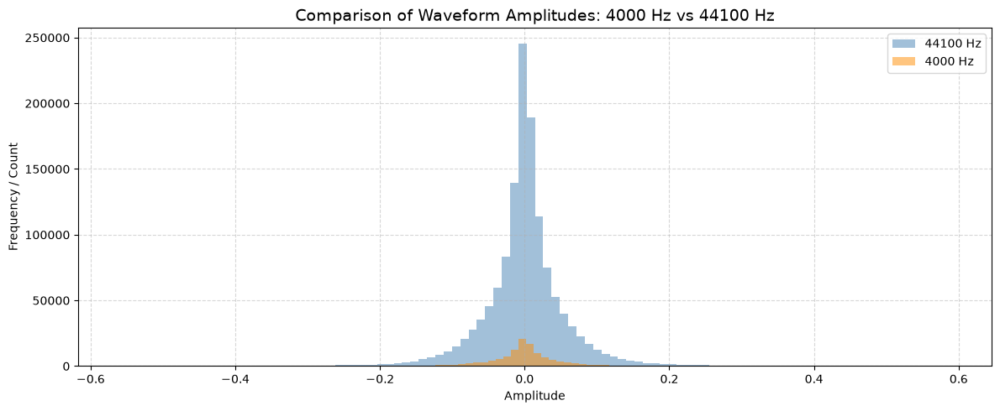

In [7]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    # plot a histogram of the waveform amplitudes at 4000Hz vs 44100 Hz
    # Load the audio at both sample rates
    y_4k, _ = librosa.load(small['audio_path'].iloc[10], sr=4000)
    y_44k, _ = librosa.load(small['audio_path'].iloc[10], sr=44100)

    # Plotting the histogram of the waveform amplitudes
    plt.figure(figsize=(12, 5))

    # Overlaid histograms
    plt.hist(y_44k, bins=100, alpha=0.5, label='44100 Hz', color='steelblue', edgecolor='none')
    plt.hist(y_4k, bins=100, alpha=0.5, label='4000 Hz', color='darkorange', edgecolor='none')

    plt.title('Comparison of Waveform Amplitudes: 4000 Hz vs 44100 Hz', fontsize=14)
    plt.xlabel('Amplitude')
    plt.ylabel('Frequency / Count')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

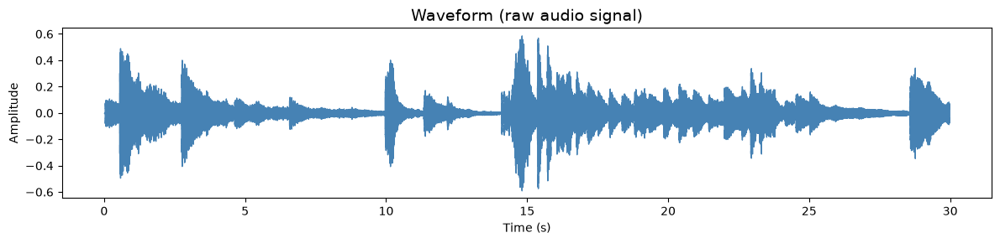

In [8]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    # Display waveform for a single example

    plt.figure(figsize=(12, 3))              # create a wide, short figure (12 wide, 3 tall)
    librosa.display.waveshow(y, sr=sr, color='steelblue')  # plot amplitude over time
    plt.title('Waveform (raw audio signal)', fontsize=14)  # figure title
    plt.xlabel('Time (s)')                   # x-axis: time in seconds
    plt.ylabel('Amplitude')                  # y-axis: amplitude (-1.0 to +1.0)
    plt.tight_layout()                       # remove excess whitespace around the plot
    plt.show()      

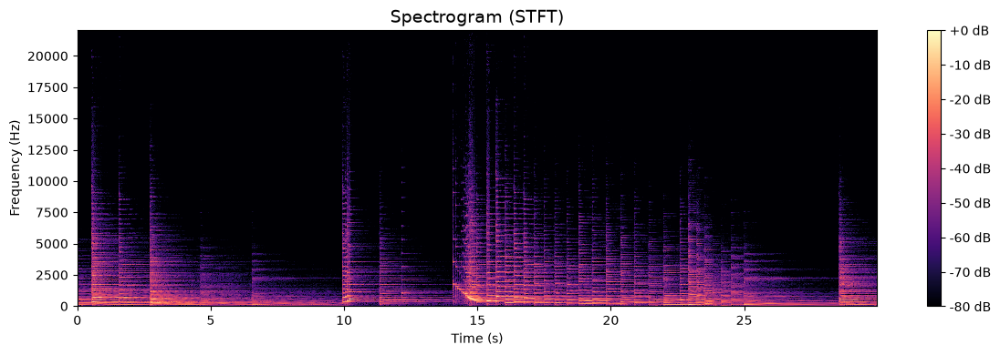

In [9]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    # Compute the Short-Time Fourier Transform (STFT)
    # splits the audio into short overlapping windows and computes
    # the frequency content of each window
    D = librosa.stft(y)

    # Convert complex STFT output to decibels (dB) for visualisation
    # np.abs(D), magnitude (discard phase information)
    # ref=np.max, normalise relative to the loudest frequency (sets the loudest value as 0 dB reference)
    D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(D_db, sr=sr, x_axis='time', y_axis='hz', cmap='magma')  # plot frequency over time
    plt.colorbar(format='%+2.0f dB')        # colour bar showing intensity in decibels
    plt.title('Spectrogram (STFT)', fontsize=14)
    plt.xlabel('Time (s)')                  # x-axis: time in seconds
    plt.ylabel('Frequency (Hz)')            # y-axis: frequency in Hz (linear scale)
    plt.tight_layout()
    plt.show()

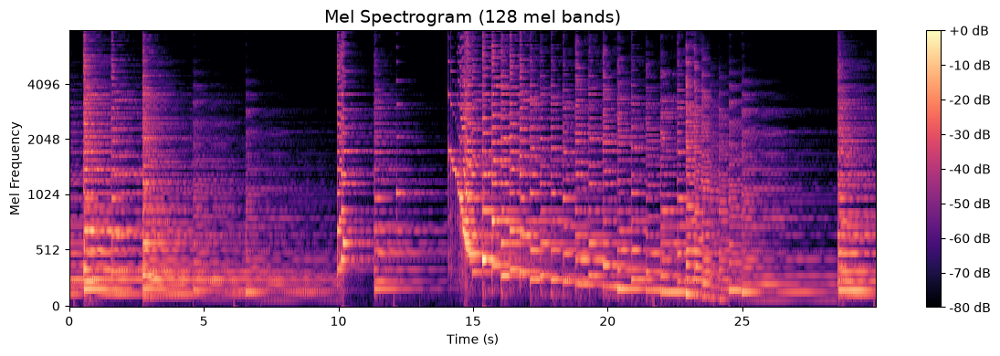

In [10]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    # Compute mel spectrogram
    # n_mels=128: number of mel frequency bands (more bands = more frequency detail)
    # fmax=8000: only consider frequencies up to 8000 Hz (covers most speech and music)
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)

    # Convert power to decibels (dB) for visualisation
    # power_to_db (vs amplitude_to_db above) because melspectrogram returns power, not amplitude
    # ref=np.max, normalise relative to the loudest frequency (0 dB = loudest)
    S_db = librosa.power_to_db(S, ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', fmax=8000, cmap='magma')  # y_axis='mel' -> perceptual frequency scale
    plt.colorbar(format='%+2.0f dB')                                                             # colour bar showing intensity in decibels
    plt.title('Mel Spectrogram (128 mel bands)', fontsize=14)
    plt.xlabel('Time (s)')
    plt.ylabel('Mel Frequency')                                                                  # mel scale: compressed at high frequencies
    plt.tight_layout()
    plt.show()

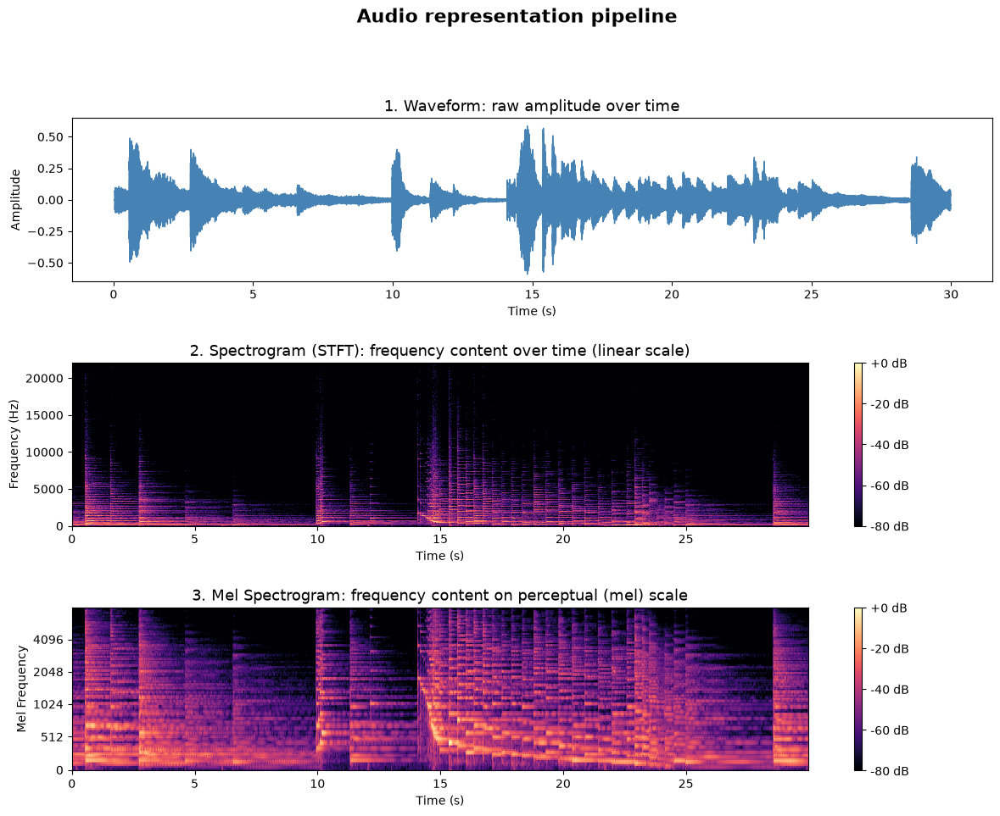

In [11]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.3] Skipped - raw audio not available.')
else:
    fig = plt.figure(figsize=(14, 10))
    gs = gridspec.GridSpec(3, 1, hspace=0.5)

    # --- Waveform ---
    ax1 = fig.add_subplot(gs[0])
    librosa.display.waveshow(y, sr=sr, ax=ax1, color='steelblue')
    ax1.set_title('1. Waveform: raw amplitude over time', fontsize=13)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Amplitude')

    # --- Spectrogram (STFT) ---
    ax2 = fig.add_subplot(gs[1])
    img2 = librosa.display.specshow(D_db, sr=sr, x_axis='time', y_axis='hz', cmap='magma', ax=ax2)
    fig.colorbar(img2, ax=ax2, format='%+2.0f dB')
    ax2.set_title('2. Spectrogram (STFT): frequency content over time (linear scale)', fontsize=13)
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Frequency (Hz)')

    # --- Mel Spectrogram ---
    ax3 = fig.add_subplot(gs[2])
    img3 = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', fmax=8000, cmap='magma', ax=ax3)
    fig.colorbar(img3, ax=ax3, format='%+2.0f dB')
    ax3.set_title('3. Mel Spectrogram: frequency content on perceptual (mel) scale', fontsize=13)
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Mel Frequency')

    plt.suptitle('Audio representation pipeline', fontsize=16, fontweight='bold', y=1.01)
    plt.savefig('audio_pipeline.png', dpi=150, bbox_inches='tight')
    plt.show()

### 2.4 Conversion function

Loads an MP3 at 22,050 Hz mono, rejects empty / non-finite / completely silent audio,
pads or truncates to exactly 30 seconds, then computes a mel spectrogram and converts
power to dB relative to the peak (`top_db=80`, so the range is `[-80, 0]`).

Uniform output shape: `(128, 1292)`.

In [12]:
def mp3_to_melspec(path):
    # librosa loads MP3 through the installed audio backend
    try:
        y, sr = librosa.load(path, sr=cfg.sr, mono=True)

        if y.size == 0 or not np.isfinite(y).all():
            raise ValueError("Audio is empty or contains non-finite samples.")

        # Also check for complete silence (all zeros) in the audio signal - will remove 1 track (track 107535) from the dataset
        if np.all(y == 0):
            raise ValueError("Audio is completely silent (all zeros).")

        # Measure before padding/truncation
        loaded_duration = len(y) / sr

        # Make every waveform exactly 30 seconds
        y = librosa.util.fix_length(y, size=sr * 30)
    
        # Compute mel spectrogram
        # n_mels=128: number of mel frequency bands (more bands = more frequency detail)
        # fmax=8000: only consider frequencies up to 8000 Hz (covers most speech and music)
        S = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_fft=cfg.n_fft,
            hop_length=cfg.hop_length,
            n_mels=cfg.n_mels,
            fmax=cfg.fmax,
            center=True
        )

        # Convert power to decibels (dB) for visualisation
        # power_to_db (vs amplitude_to_db above) because melspectrogram returns power, not amplitude
        # ref=np.max, normalise relative to the loudest frequency (0 dB = loudest)
        S_db = librosa.power_to_db(S, ref=np.max, top_db=cfg.top_db)

        return y, sr, S, S_db, loaded_duration, None

    except Exception as exc:
        return None, None, None, None, np.nan, str(exc)

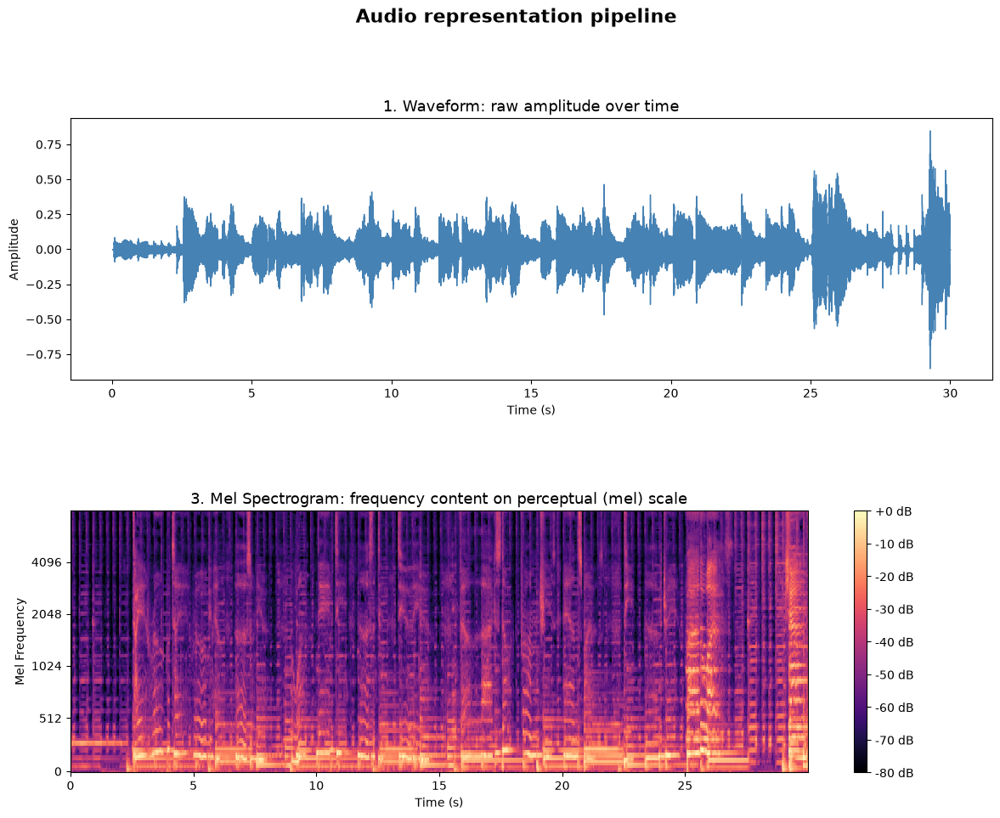

In [13]:
if not (HAVE_AUDIO and HAVE_METADATA):
    print('[2.4] Skipped - raw audio not available.')
else:
    # Try with one example first to validate function works as intended
    first_id = small['audio_path'].iloc[3]
    y, sr, S, S_db, loaded_duration, error = mp3_to_melspec(first_id)

    if error is not None:
        raise RuntimeError(error)

    fig = plt.figure(figsize=(14, 10))
    gs = gridspec.GridSpec(2, 1, hspace=0.5)

    # --- Waveform ---
    ax1 = fig.add_subplot(gs[0])
    librosa.display.waveshow(y, sr=sr, ax=ax1, color='steelblue')
    ax1.set_title('1. Waveform: raw amplitude over time', fontsize=13)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Amplitude')

    # --- Mel Spectrogram ---
    ax3 = fig.add_subplot(gs[1])
    img3 = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel', fmax=8000, cmap='magma', ax=ax3)
    fig.colorbar(img3, ax=ax3, format='%+2.0f dB')
    ax3.set_title('3. Mel Spectrogram: frequency content on perceptual (mel) scale', fontsize=13)
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Mel Frequency')

    plt.suptitle('Audio representation pipeline', fontsize=16, fontweight='bold', y=1.01)
    plt.show()

### 2.5 Batch conversion

Resumable - skips any track whose `.npy` already exists, and checkpoints the manifest
every 100 tracks, so a crashed or disconnected run picks up where it left off.
Failures are logged to `conversion_results.csv` rather than killing the loop.


In [14]:
if (RELOADED):
    print('MP3 Conversion Skipped - spectrograms already cached.')
else:
    selected_ids = (
        small.index[:cfg.max_tracks]
        if cfg.max_tracks is not None
        else small.index
    )

    results = small.loc[selected_ids, ["genre", "split", "audio_path"]].copy()
    results["loaded_duration_seconds"] = np.nan
    results["mel_path"] = None
    results["conversion_error"] = None
    results["status"] = "pending"

    cfg.output_dir.mkdir(parents=True, exist_ok=True)
    manifest_path = cfg.output_dir / "conversion_results.csv"

    # Check if previous manifest exists and load it to resume processing
    if manifest_path.is_file():
        previous_results = pd.read_csv(manifest_path, index_col="track_id")
        for col in ["loaded_duration_seconds", "mel_path", "conversion_error", "status"]:
            if col in previous_results.columns:
                results[col] = previous_results[col].reindex(results.index)
        print("Existing manifest found with", len(previous_results), "records.")
    
    expected_shape = (
        cfg.n_mels,
        1 + (cfg.sr * 30) // cfg.hop_length
    )

    total = len(results)
    start = perf_counter()

    print("Processing, total=", total, " tracks")
    print("Output directory:", cfg.output_dir.resolve())

    for count, track_id in enumerate(results.index, start=1):
        mel_path = cfg.output_dir / f"{int(track_id):06d}.npy"

        # Check if file already exists and marked successful
        if mel_path.is_file():
            results.at[track_id, "mel_path"] = str(mel_path)
            results.at[track_id, "status"] = "success"
            if pd.isna(results.at[track_id, "loaded_duration_seconds"]):
                results.at[track_id, "loaded_duration_seconds"] = 30.0
            continue
    
        audio_path = results.at[track_id, "audio_path"]

        try:
            y, sr, S, S_db, duration, error = mp3_to_melspec(audio_path)

            if error is not None:
                raise RuntimeError(error)

            results.at[track_id, "loaded_duration_seconds"] = duration
            mel = S_db.astype(np.float32)
        
            if mel.shape != expected_shape:
                raise ValueError(f"Unexpected shape: {mel.shape}")

            if not np.isfinite(mel).all():
                raise ValueError("Spectrogram contains NaN or infinity.")

            mel_path = cfg.output_dir / f"{int(track_id):06d}.npy"
            np.save(mel_path, mel)

            # Verify the file can be read
            saved = np.load(mel_path)

            results.at[track_id, "mel_path"] = str(mel_path)
            results.at[track_id, "status"] = "success"

        except Exception as exc:
            results.at[track_id, "conversion_error"] = str(exc)
            results.at[track_id, "status"] = "failed"

        if count % 100 == 0 or count == total:
            results.to_csv(manifest_path)

            elapsed = perf_counter() - start
            remaining_minutes = (elapsed / count) * (total - count) / 60

            succeeded = (results["status"] == "success").sum()
            failed = (results["status"] == "failed").sum()

            print(
                f"{count}/{total} | "
                f"success={succeeded}, failed={failed} | "
                f"elapsed={elapsed / 60:.1f} min | "
                f"estimated remaining={remaining_minutes:.1f} min"
            )

    successful = results["status"] == "success"
    failed_results = results.loc[results["status"] == "failed"]

    print("Successfully converted:", successful.sum())
    print("Failed conversions:", len(failed_results))
    print("Expected mel shape:", expected_shape)
    print("Max original loaded duration:", results.loc[successful, "loaded_duration_seconds"].max(), "seconds")
    print("Min original loaded duration:", results.loc[successful, "loaded_duration_seconds"].min(), "seconds")
    print("Saved processing record:", manifest_path)

    display(failed_results[["audio_path", "conversion_error"]])

MP3 Conversion Skipped - spectrograms already cached.


In [15]:
if not (not RELOADED):
    print('[2.5] Skipped - spectrograms already cached.')
else:
    ready_all = results.loc[results["status"] == "success"].copy()
    track_id = ready_all.index[0]
    mel = np.load(ready_all.at[track_id, "mel_path"])

    fig, ax = plt.subplots(figsize=(12, 4))
    image = librosa.display.specshow(
        mel,
        sr=cfg.sr,
        hop_length=cfg.hop_length,
        x_axis="time",
        y_axis="mel",
        fmax=cfg.fmax,
        cmap="magma",
        ax=ax
    )
    fig.colorbar(image, ax=ax, format="%+2.0f dB")
    ax.set_title(f"Saved mel spectrogram - Track {track_id}")
    plt.show()

[2.5] Skipped - spectrograms already cached.


### 2.6 Leakage checks

Verify FMA's split actually holds: **no artist appears in more than one split.**

Since tracks from one album share production, mastering, and often instrumentation, 
this is a weaker but real leakage channel. Flagged for EDA in Section 3.

In [16]:
if not (HAVE_METADATA and not RELOADED):
    print('[2.6] Skipped - see the cached-data leakage check below.')
else:
    small_meta = tracks.loc[tracks[("set", "subset")] == "small"].copy()

    # Extract artist and album IDs
    artist_ids = small_meta[("artist", "id")]
    album_ids = small_meta[("album", "id")]
    splits = small_meta[("set", "split")]

    # Create dfs for artists within each dataset (train, val, test)
    train_artists = set(artist_ids[splits == "training"])
    val_artists   = set(artist_ids[splits == "validation"])
    test_artists  = set(artist_ids[splits == "test"])

    # Check for artist intersections across datasets
    train_val_artists_leak = train_artists.intersection(val_artists)
    train_test_artists_leak = train_artists.intersection(test_artists)
    val_test_artists_leak = val_artists.intersection(test_artists)

    # Print Results
    print("Unique artists - Train:", len(train_artists), "Val:", len(val_artists), "Test:", len(test_artists))
    print("Artist overlap Train vs Val:  ", len(train_val_artists_leak))
    print("Artist overlap Train vs Test: ", len(train_test_artists_leak))
    print("Artist overlap Val vs Test:   ", len(val_test_artists_leak))

    # Print final conclusion based on leak results
    assert len(train_val_artists_leak) == 0 and len(train_test_artists_leak) == 0 and len(val_test_artists_leak) == 0, \
        "INVESTIGATION NEEDED: Artists overlap across splits."
    print("PASS: No artist leakage across splits. The FMA split is artist-conditional.")

    # Create dfs for albums within each dataset (train, val, test)
    train_albums = set(album_ids[splits == "training"])
    val_albums   = set(album_ids[splits == "validation"])
    test_albums  = set(album_ids[splits == "test"])

    # Check for album intersections across datasets
    train_val_album_leak = train_albums.intersection(val_albums)
    train_test_album_leak = train_albums.intersection(test_albums)
    val_test_album_leak = val_albums.intersection(test_albums)
    overlapping_albums = (train_albums & val_albums) | (train_albums & test_albums) | (val_albums & test_albums)

    # Print Results
    print("Unique albums - Train:", len(train_albums), "Val:", len(val_albums), "Test:", len(test_albums))
    print("Album overlap Train vs Val:  ", len(train_val_album_leak))
    print("Album overlap Train vs Test: ", len(train_test_album_leak))
    print("Album overlap Val vs Test:   ", len(val_test_album_leak))
    print("Overlapping albums across splits:", len(overlapping_albums))

    # Print final conclusion based on leak results
    print("INVESTIGATION NEEDED: 90 Albums overlap across splits. Flagging for deeper analysis via EDA.")

[2.6] Skipped - see the cached-data leakage check below.


In [17]:
# --- Leakage check on cached data ---
# The full check above needs tracks.csv. The split CSVs already carry artist_id and
# album_id, so the same check runs directly on the reloaded data.
if RELOADED:
    sets = {name: df for name, df in [("train", train), ("val", val), ("test", test)]}

    for col, label in [("artist_id", "Artist"), ("album_id", "Album")]:
        ids = {name: set(df[col].dropna()) for name, df in sets.items()}
        print(f"Unique {label.lower()}s - " +
              " ".join(f"{n.capitalize()}: {len(v)}" for n, v in ids.items()))
        for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
            overlap = ids[a] & ids[b]
            print(f"  {label} overlap {a} vs {b}: {len(overlap)}")
        print()

    artist_overlap = sum(
        len(set(sets[a]["artist_id"].dropna()) & set(sets[b]["artist_id"].dropna()))
        for a, b in [("train", "val"), ("train", "test"), ("val", "test")]
    )
    assert artist_overlap == 0, "INVESTIGATION NEEDED: artists overlap across splits."
    print("PASS: No artist leakage across splits. The FMA split is artist-conditional.")
    print("INVESTIGATION NEEDED: albums overlap across splits. Flagged for EDA (Section 3.3).")

Unique artists - Train: 1886 Val: 219 Test: 202
  Artist overlap train vs val: 0
  Artist overlap train vs test: 0
  Artist overlap val vs test: 0

Unique albums - Train: 2008 Val: 278 Test: 285
  Album overlap train vs val: 58
  Album overlap train vs test: 49
  Album overlap val vs test: 21

PASS: No artist leakage across splits. The FMA split is artist-conditional.
INVESTIGATION NEEDED: albums overlap across splits. Flagged for EDA (Section 3.3).


### 2.7 Export splits

Writes `train_mel.csv` / `val_mel.csv` / `test_mel.csv` with genre, integer `genre_id`,
the `.npy` path, and artist/album metadata, plus `genre_mapping.csv` so the label encoding
is fixed once and reused by every downstream notebook.

The `max_tracks` guard prevents exporting partial splits from a benchmark run.

In [18]:
if (RELOADED):
    print('Data Splits Skipped - split CSVs already exist in data > tracked.')
else:
    if cfg.max_tracks is not None:
        raise RuntimeError(
            "Not creating CSV exports if cfg.max_tracks is set so only a sample runs.", 
            "Set cfg.max_tracks = None to process the full dataset before exporting."
        )

    ready_all = results.loc[results["status"] == "success"].copy()

    # Create genre integer mapping for modeling
    genre_names = sorted(ready_all["genre"].unique())
    genre_to_id = {genre: idx for idx, genre in enumerate(genre_names)}
    ready_all["genre_id"] = ready_all["genre"].map(genre_to_id)

    # Add in artist and album metadata from tracks.csv
    ready_all["artist_id"] = small_meta.loc[ready_all.index, ("artist", "id")]
    ready_all["artist_name"] = small_meta.loc[ready_all.index, ("artist", "name")]
    ready_all["album_id"] = small_meta.loc[ready_all.index, ("album", "id")]
    ready_all["album_title"] = small_meta.loc[ready_all.index, ("album", "title")]

    # Identify columns to export and tracked path location
    cols_to_export = [
        "genre", 
        "genre_id", 
        "mel_path", 
        "artist_id", 
        "artist_name", 
        "album_id", 
        "album_title", 
        "loaded_duration_seconds"
    ]
    tracked_dir = Path("../data/tracked")
    tracked_dir.mkdir(parents=True, exist_ok=True)

    train_rows = ready_all.loc[ready_all["split"] == "training"].copy()
    val_rows = ready_all.loc[ready_all["split"] == "validation"].copy()
    test_rows = ready_all.loc[ready_all["split"] == "test"].copy()

    print("Training:", len(train_rows))
    print("Validation:", len(val_rows))
    print("Test:", len(test_rows))

    # Save the processed mel spectrograms and metadata to CSV files for each split
    for split_name, filename in [
        ("training", "train_mel.csv"),
        ("validation", "val_mel.csv"),
        ("test", "test_mel.csv")
    ]:
        subset = ready_all.loc[ready_all["split"] == split_name, cols_to_export]
        out_path = tracked_dir / filename
        subset.to_csv(out_path, index_label="track_id")
        print(f"Saved, {filename}: {len(subset)} records -> {out_path}")

    # Check how failed conversion affected genre counts
    display(pd.crosstab(ready_all["split"], ready_all["genre"]))

    # Save Genre Mapping for future reference
    genre_mapping_df = pd.DataFrame(
        list(genre_to_id.items()), 
        columns=["genre", "genre_id"]
    )
    genre_mapping_path = tracked_dir / "genre_mapping.csv"
    genre_mapping_df.to_csv(genre_mapping_path, index=False)
    print("Saved genre mapping to:", genre_mapping_path)
    display(genre_mapping_df)

    # Save the failed track IDs and errors for documentation
    print("\nFailed conversions:", len(results.loc[results["status"] == "failed"]))
    display(
        results.loc[
            results["status"] == "failed",
            ["genre", "split", "conversion_error"]
        ]
    )

Data Splits Skipped - split CSVs already exist in data > tracked.


---
## <span style="color: chocolate;">3 · Data Pipeline: EDA & Feature Engineering</span>
**EDA on the training split.** Turn cached spectrograms into model-ready tensors.

Check for missing values, corrupt MP3s, outliers, scaling, normalization, feature selection.

#### EDA inputs
* Train only → spectrograms
* Train only → raw mp3 files
* Train only → tracks table (with features)

#### Purpose
Investigate the training data using the features table, the raw audio, or the spectrograms
(average intensity per mel band per genre, and so on).

#### Outputs
Various EDA visuals for the training set.


### 3.0 Resolve the data source

Section 3 runs identically whether Section 2 reloaded the cache or rebuilt it from scratch.
This cell picks up `train` / `val` / `test` from whichever path ran and **filters EDA to
the training split**.

In [19]:
# --- Resolve train/val/test regardless of which Section 2 path ran ---
if not RELOADED:
    ready_all["mel_path"] = [cfg.output_dir / f"{int(t):06d}.npy" for t in ready_all.index]
    train = ready_all.loc[ready_all["split"] == "training"].copy()
    val   = ready_all.loc[ready_all["split"] == "validation"].copy()
    test  = ready_all.loc[ready_all["split"] == "test"].copy()
    genre_to_id = {g: i for i, g in enumerate(sorted(ready_all["genre"].unique()))}
    id_to_genre = {v: k for k, v in genre_to_id.items()}

print(f"train {len(train)} | val {len(val)} | test {len(test)}")
print("genres:", list(genre_to_id))

# EDA is TRAINING ONLY - looking at val/test before modeling leaks information
# into our design decisions.
eda = train

train 6393 | val 800 | test 800
genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']


Standard loader used from here on - normalizes dB `[-80, 0]` to `[0, 1]` and adds a channel
dimension. Defined here because Section 3.2 already needs it; Section 7 reuses it for
newly uploaded audio.

In [20]:
def load_mel_tensor(npy_path):
    """
    Loads a saved mel spectrogram, normalizes dB [-80, 0] to [0, 1] and adds a channel dimension: (128, 1292, 1).
    """
    mel = np.load(npy_path).astype(np.float32)
    # Normalize to [0, 1]
    normalized = (np.clip(mel, -80.0, 0.0) + 80.0) / 80.0
    return np.expand_dims(normalized, axis=-1)

### 3.1 Spectrogram integrity and energy distribution

Confirms every array is `(128, 1292)` float32 with no NaN/Inf and a dB range inside
`[-80, 0]`, then plots mean energy per mel band - on the training split only.

All shapes match expected (128, 1292): True
All dtypes are float32: True
Any NaNs detected: False
Any Infs detected: False
Max dB across tracks (should be 0.0 dB): 0.0 dB (min: 0.0 dB)
Min dB floor (should be >= -80.0 dB): -80.0 dB
Mean dB range: -77.73517608642578 dB -13.797280311584473 dB


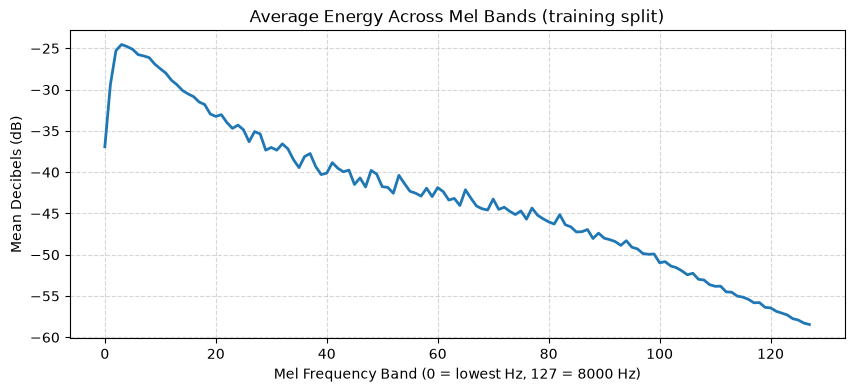

In [21]:
if not (HAVE_NPY):
    print('[3.1] Skipped - full .npy cache not present (compact-only mode).')
else:
    # Adapted from 02_DataPreProcessing_Full.ipynb Step 6 to run on the training split
    stats = []
    mean_mel_energy = np.zeros(cfg.n_mels)
    paths = eda["mel_path"].tolist()

    for path in paths:
        arr = np.load(path)
        mean_mel_energy += arr.mean(axis=1)
        stats.append({
            "shape": arr.shape,
            "dtype": str(arr.dtype),
            "min_db": float(arr.min()),
            "max_db": float(arr.max()),
            "mean_db": float(arr.mean()),
            "std_db": float(arr.std()),
            "has_nan": bool(np.isnan(arr).any()),
            "has_inf": bool(np.isinf(arr).any()),
        })

    mean_mel_energy /= len(paths)
    df_stats = pd.DataFrame(stats)

    print("All shapes match expected (128, 1292):", (df_stats["shape"] == (128, 1292)).all())
    print("All dtypes are float32:", (df_stats["dtype"] == "float32").all())
    print("Any NaNs detected:", df_stats["has_nan"].any())
    print("Any Infs detected:", df_stats["has_inf"].any())
    print("Max dB across tracks (should be 0.0 dB):", df_stats["max_db"].max(),
          "dB (min:", df_stats["max_db"].min(), "dB)")
    print("Min dB floor (should be >= -80.0 dB):", df_stats["min_db"].min(), "dB")
    print("Mean dB range:", df_stats["mean_db"].min(), "dB", df_stats["mean_db"].max(), "dB")

    plt.figure(figsize=(10, 4))
    plt.plot(range(cfg.n_mels), mean_mel_energy, lw=2)
    plt.title("Average Energy Across Mel Bands (training split)")
    plt.xlabel("Mel Frequency Band (0 = lowest Hz, 127 = 8000 Hz)")
    plt.ylabel("Mean Decibels (dB)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

### 3.2 Sample spectrograms by genre (full resolution)

Needs the full `.npy` cache. Section 3.6 draws the same figure from the compact cache and
always runs.

Sample array: (8, 128, 1292, 1)
Value range: 0.0 to 1.0


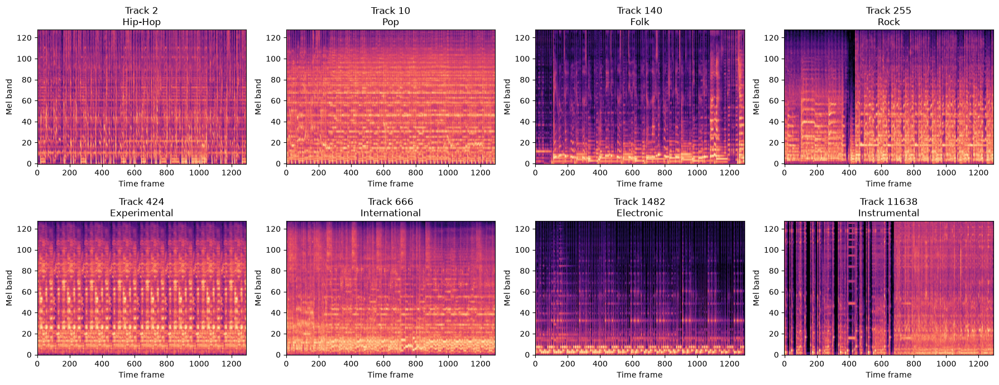

In [22]:
if not (HAVE_NPY):
    print('[3.2] Skipped - full .npy cache not present. See 3.6 for a compact-cache version.')
else:
    # One example per genre, loaded through the standard normalization
    sample_ids = eda.groupby("genre").head(1).index
    X_sample = np.stack([load_mel_tensor(eda.at[t, "mel_path"]) for t in sample_ids])
    y_sample = eda.loc[sample_ids, "genre"].map(genre_to_id).to_numpy(dtype=np.int64)

    print("Sample array:", X_sample.shape)
    print("Value range:", X_sample.min(), "to", X_sample.max())

    n = len(sample_ids)
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off")
            continue
        ax.imshow(X_sample[i, :, :, 0], origin="lower", aspect="auto",
                  cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"Track {sample_ids[i]}\n{eda.loc[sample_ids[i], 'genre']}")
        ax.set_xlabel("Time frame")
        ax.set_ylabel("Mel band")
    plt.tight_layout()
    plt.show()

### 3.3 Remaining EDA

In [23]:
# --- EDA (training split only) ---
# train = pd.read_csv("../data/tracked/train_mel.csv", index_col="track_id")

# TODO: Fig 1  class balance bar chart (confirm ~1000/genre survives the 7 dropped tracks)
# TODO: Fig 2  loaded_duration_seconds histogram (which tracks needed padding?)
# TODO: Fig 3  mean mel spectrogram per genre (2x4 grid, shared vmin/vmax)
# TODO: Fig 4  box plots of mean/std dB by genre
# TODO: Fig 5  correlation heatmap on features.csv subset
# TODO: Fig 6  PCA / t-SNE of features.csv colored by genre -> previews class separability
# TODO: Fig 7  pixel intensity distribution -> sanity-check the [0,1] normalization

# --- Flagged from Section 2.6 ---
# TODO: analyze the 90 overlapping albums across splits
#       how many TRACKS are affected? concentrated in particular genres?
#       decide and document: accept, or drop the affected val/test tracks
# TODO: artist distribution across splits/genres; check for compilation albums
#       (a compilation credited to one "artist" can span many real artists)

# NOTE: every figure needs labeled axes, a title, a legend where relevant,
#       and a written interpretation in the report

### 3.4 Feature engineering

#### Inputs
* Separated train / validation / test spectrograms
* Train / validation / test tracks tables - only the outcome variable (genre) is used here

#### Purpose
* Turn all three splits into a usable matrix (`num_songs` × `num_features`, plus a genre column)
* Normalize - and if so, **to training-set scales only**
* Make the outcome categorical (0–7)

#### Outputs
Three tables ready for the modeling pipeline. Save large files to `data/local/`,
small ones to `data/tracked/`.

> **Size problem - resolved in Section 3.5.** The cached arrays are `(128, 1292)` =
> 165,376 pixels per track. Flattened, the training matrix would be 6,393 × 165,376
> float32 ≈ **4.2 GB**: too large to hold for logistic regression. 
> Section 3.5 pools the time axis to 128 frames and stores float16, bringing
> the flattened matrix to ~419 MB.

`load_mel_tensor()` is already defined in Section 3.0 and is still the right loader for
the full-resolution arrays (Section 3.2, and Section 7's UI).

### 3.5 Compact cache - time pooling + float16

Builds a second, much smaller cache **from the existing `.npy` files** - no re-reading of
MP3s required.

Two reductions:

**1. Pool the time axis.** 1292 frames → 128 by averaging each run of 10 consecutive
frames. 128 × 10 = 1280, so the final 12 frames (0.28s of 30s) are dropped. Averaging is
equivalent to computing the spectrogram with a 10× longer
hop, and it preserves the energy in each band rather than discarding frames.

**2. Cast to float16.** dB values span `[-80, 0]`; float16 resolves that to about
0.06 dB, giving a measured round-trip error under **0.03 dB** - far below what the
model can use.

| | Per track | All 8,000 |
|---|---|---|
| float32, 128 × 1292 | 646 KB | 5.3 GB |
| **float16, 128 × 128** | **32 KB** | **~262 MB** (~200 MB compressed) |

The result is one portable `.npz` that can be downloaded instead of re-converting for an
hour, and it resolves the memory problem when flattened, the training matrix
is now 6,393 × 16,384 ≈ 419 MB in float32, which a baseline model can actually hold.

Change `cfg.target_frames` to keep more time resolution (256 pools by 5, 128 by 10).
Delete `mel_compact.npz` to force a rebuild.

In [24]:
# --- Time-axis pooling ---
def resize_time(mel, target_frames):
    """(n_mels, n_frames) -> (n_mels, target_frames) by average-pooling the time axis.

    Equivalent to a longer hop length. Frames that don't divide evenly are dropped
    from the end (12 of 1292 when target_frames=128).
    """
    n_mels, n_frames = mel.shape
    factor = n_frames // target_frames
    if factor < 1:
        raise ValueError(f"target_frames={target_frames} exceeds n_frames={n_frames}")
    usable = factor * target_frames
    return mel[:, :usable].reshape(n_mels, target_frames, factor).mean(axis=2)


def build_compact(df, cfg):
    """Stack a split's spectrograms into one pooled, float16 array."""
    X = np.empty((len(df), cfg.n_mels, cfg.target_frames), dtype=cfg.compact_dtype)
    for i, path in enumerate(df["mel_path"]):
        mel = np.load(path).astype(np.float32)          # pool in float32
        X[i] = resize_time(mel, cfg.target_frames).astype(cfg.compact_dtype)
    y = df["genre_id"].to_numpy(dtype=np.int64)
    return X, y

In [25]:
# --- Build (or load) the compact cache ---
if cfg.compact_path.is_file():
    print("Loading existing compact cache:", cfg.compact_path)
    with np.load(cfg.compact_path, allow_pickle=False) as z:
        X_train, y_train = z["X_train"], z["y_train"]
        X_val,   y_val   = z["X_val"],   z["y_val"]
        X_test,  y_test  = z["X_test"],  z["y_test"]
        ids_train, ids_val, ids_test = z["ids_train"], z["ids_val"], z["ids_test"]
else:
    print(f"Building compact cache: pooling {1 + (cfg.sr * 30) // cfg.hop_length} "
          f"-> {cfg.target_frames} frames, casting to {cfg.compact_dtype} ...")
    from time import perf_counter
    t0 = perf_counter()

    X_train, y_train = build_compact(train, cfg)
    X_val,   y_val   = build_compact(val,   cfg)
    X_test,  y_test  = build_compact(test,  cfg)
    ids_train = train.index.to_numpy()
    ids_val   = val.index.to_numpy()
    ids_test  = test.index.to_numpy()

    cfg.compact_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        cfg.compact_path,
        X_train=X_train, y_train=y_train, ids_train=ids_train,
        X_val=X_val,     y_val=y_val,     ids_val=ids_val,
        X_test=X_test,   y_test=y_test,   ids_test=ids_test,
    )
    print(f"Built in {perf_counter() - t0:.0f}s -> {cfg.compact_path}")

for name, X, y in [("train", X_train, y_train),
                   ("val",   X_val,   y_val),
                   ("test",  X_test,  y_test)]:
    print(f"  {name:<5} X={X.shape} {X.dtype}  y={y.shape}  "
          f"{X.nbytes / 1e6:6.1f} MB in memory")

print(f"\nOn disk: {cfg.compact_path.stat().st_size / 1e6:.0f} MB")
print(f"dB range: [{X_train.min():.1f}, {X_train.max():.1f}]")

Loading existing compact cache: ..\data\local\mel_compact.npz
  train X=(6393, 128, 128) float16  y=(6393,)   209.5 MB in memory
  val   X=(800, 128, 128) float16  y=(800,)    26.2 MB in memory
  test  X=(800, 128, 128) float16  y=(800,)    26.2 MB in memory

On disk: 200 MB
dB range: [-80.0, -0.1]


float16 round-trip error over 25 tracks:
  max 0.0312 dB | mean 0.0291 dB
  (dB range is 80, so this is well under 0.1% of the signal range)

PASS: compact cache is sound.


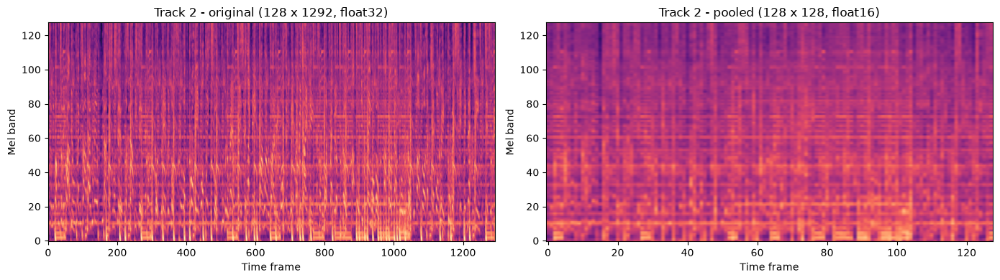

In [26]:
if not (HAVE_NPY):
    print('[3.5] Verification skipped - full .npy cache not present (compact-only mode).')
else:
    # --- Verify the reduction is lossless enough to rely on ---
    check_ids = train.index[:25]
    errors = []
    for tid in check_ids:
        full_mel = np.load(train.at[tid, "mel_path"]).astype(np.float32)
        pooled32 = resize_time(full_mel, cfg.target_frames)
        pooled16 = X_train[np.where(ids_train == tid)[0][0]].astype(np.float32)
        errors.append(np.abs(pooled16 - pooled32).max())

    print(f"float16 round-trip error over {len(check_ids)} tracks:")
    print(f"  max {np.max(errors):.4f} dB | mean {np.mean(errors):.4f} dB")
    print("  (dB range is 80, so this is well under 0.1% of the signal range)")

    assert np.max(errors) < 0.1, "float16 error larger than expected - investigate"
    assert not np.isnan(X_train).any(), "NaNs in compact cache"
    print("\nPASS: compact cache is sound.")

    # Visual check - same track, before and after
    tid = train.index[0]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].imshow(np.load(train.at[tid, "mel_path"]), origin="lower", aspect="auto",
                   cmap="magma", vmin=-80, vmax=0)
    axes[0].set_title(f"Track {tid} - original (128 x 1292, float32)")
    axes[1].imshow(X_train[0].astype(np.float32), origin="lower", aspect="auto",
                   cmap="magma", vmin=-80, vmax=0)
    axes[1].set_title(f"Track {tid} - pooled ({cfg.n_mels} x {cfg.target_frames}, "
                      f"{cfg.compact_dtype})")
    for ax in axes:
        ax.set_xlabel("Time frame")
        ax.set_ylabel("Mel band")
    plt.tight_layout()
    plt.show()

In [27]:
# --- Model-ready views ---
# Normalization is the same fixed affine map as load_mel_tensor: [-80, 0] -> [0, 1].
# It is not fitted on the data, so it introduces no train/test leakage.
def normalize(X):
    return (np.clip(X.astype(np.float32), -80.0, 0.0) + 80.0) / 80.0

# CNN input: (n, mel, time, 1)
Xc_train = normalize(X_train)[..., np.newaxis]
Xc_val   = normalize(X_val)[..., np.newaxis]
Xc_test  = normalize(X_test)[..., np.newaxis]

# Baseline input: flattened to (n, n_pixels)
Xf_train = Xc_train.reshape(len(Xc_train), -1)
Xf_val   = Xc_val.reshape(len(Xc_val), -1)
Xf_test  = Xc_test.reshape(len(Xc_test), -1)

print("CNN      :", Xc_train.shape, "|", Xc_train.dtype)
print("Flattened:", Xf_train.shape, f"= {Xf_train.nbytes / 1e6:.0f} MB")
print("Labels   :", y_train.shape, "classes:", sorted(set(y_train)))
print("Range    :", Xc_train.min(), "to", Xc_train.max())

CNN      : (6393, 128, 128, 1) | float32
Flattened: (6393, 16384) = 419 MB
Labels   : (6393,) classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Range    : 0.0 to 0.99927825


### 3.6 Mean spectrogram per genre (compact cache)

Runs in every mode, since it reads `X_train` rather than individual `.npy` files.
Averaging all training clips within a genre cancels track-specific detail and leaves the
spectral signature the models actually have to separate - this is the figure to discuss
alongside the confusion matrix.

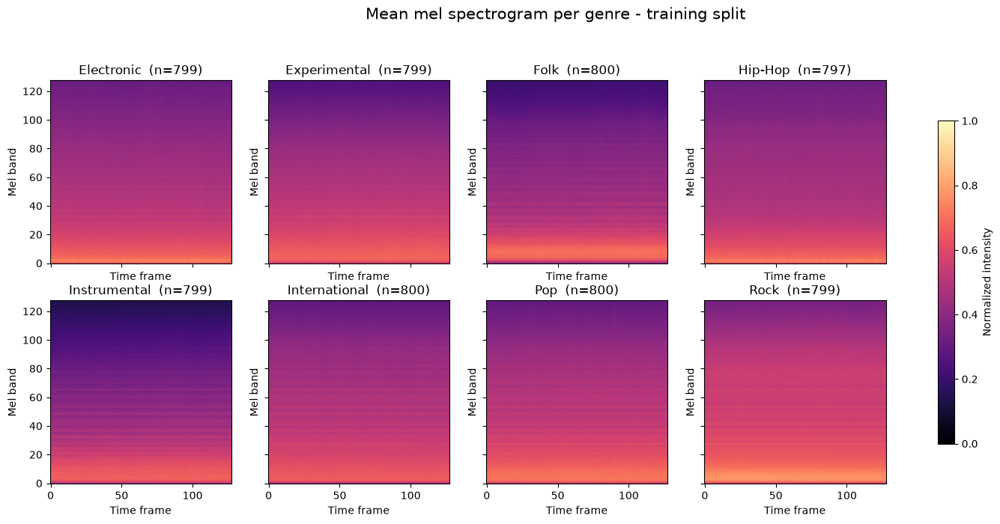

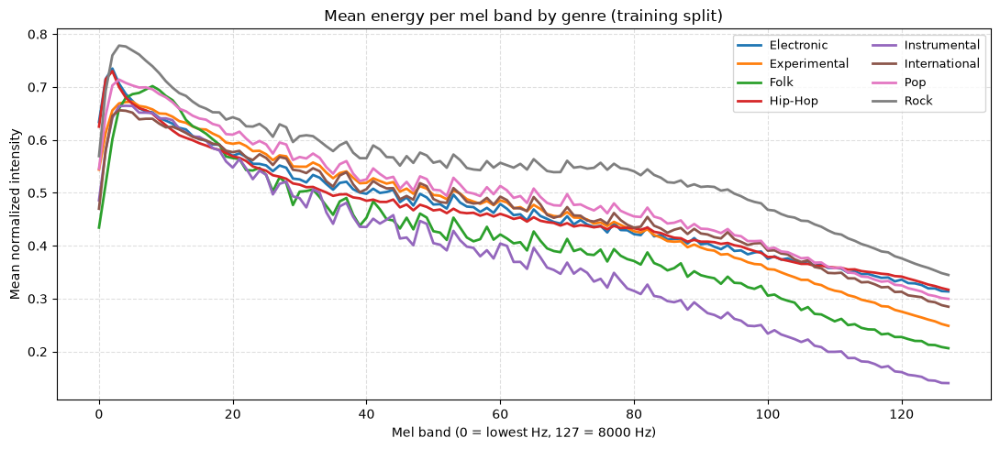

In [28]:
# --- Mean spectrogram per genre, from the compact cache (training split only) ---
genres = [id_to_genre[i] for i in range(cfg.n_classes)]

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
mean_by_genre = {}

for gid, ax in enumerate(axes.ravel()):
    mean_spec = Xc_train[y_train == gid, :, :, 0].mean(axis=0)
    mean_by_genre[genres[gid]] = mean_spec
    im = ax.imshow(mean_spec, origin="lower", aspect="auto",
                   cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{genres[gid]}  (n={(y_train == gid).sum()})")
    ax.set_xlabel("Time frame")
    ax.set_ylabel("Mel band")

fig.colorbar(im, ax=axes, shrink=0.8, label="Normalized intensity")
plt.suptitle("Mean mel spectrogram per genre - training split", fontsize=15, y=1.02)
plt.show()

# Mean energy per mel band, one line per genre - easier to read than the heatmaps
plt.figure(figsize=(11, 5))
for g, spec in mean_by_genre.items():
    plt.plot(spec.mean(axis=1), lw=2, label=g)
plt.title("Mean energy per mel band by genre (training split)")
plt.xlabel("Mel band (0 = lowest Hz, 127 = 8000 Hz)")
plt.ylabel("Mean normalized intensity")
plt.legend(ncol=2, fontsize=9)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
## <span style="color: chocolate;">4 · Methodology 1: Baseline, CNN, Train/Val/Test</span>
The baseline model is built using logistic regression. Each later model needs to beat it to
justify the added complexity.

Train on train, evaluate on validation. **`Xf_test` / `Xc_test` stay untouched until
Section 6.**

#### Shared results table
Every model is scored through `record()` so the numbers are comparable. Nothing enters the
comparison unless it went through that function.

In [29]:
# --- Shared results table (run once, before any model) ---
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

model_results = []     # NOTE: not `results` - that name holds the conversion manifest

def _labels(model, X):
    """Integer class labels from sklearn, Keras, PyTorch wrapper, or a plain function."""
    out = model(X) if callable(model) and not hasattr(model, "predict") else model.predict(X)
    out = np.asarray(out)
    return out.argmax(axis=1) if out.ndim == 2 and out.shape[1] > 1 else out.ravel()

def record(name, model, X_train, X_val, note=""):
    """Score any model on train + validation and append a row to `model_results`."""
    row = {"model": name}
    for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]:
        pred = _labels(model, X)
        row[f"{split}_acc"] = accuracy_score(y, pred)
        row[f"{split}_f1"]  = f1_score(y, pred, average="macro")
    row["gap"] = row["train_acc"] - row["val_acc"]
    row["note"] = note
    model_results.append(row)
    print(f"{name:<34} train {row['train_acc']:.3f} | val {row['val_acc']:.3f} "
          f"| val F1 {row['val_f1']:.3f} | gap {row['gap']:+.3f}")
    return pd.DataFrame(model_results)

def plot_confusion(y_true, y_pred, title):
    """Row-normalized confusion matrix: each cell is a share of the true genre."""
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred, normalize="true"),
        display_labels=[id_to_genre[i] for i in range(cfg.n_classes)],
    ).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(title)
    ax.set_xlabel("Predicted genre")
    ax.set_ylabel("True genre")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print(f"Chance accuracy: {1 / cfg.n_classes:.3f}  ({cfg.n_classes} balanced classes)")

Chance accuracy: 0.125  (8 balanced classes)


c:\Users\hzaid\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression (C=1e-4)       train 0.381 | val 0.328 | val F1 0.291 | gap +0.053

Val accuracy: 0.3275
Val macro-F1: 0.2910023995480482
               precision    recall  f1-score   support

   Electronic       0.22      0.11      0.15       100
 Experimental       0.19      0.10      0.13       100
         Folk       0.54      0.53      0.53       100
      Hip-Hop       0.31      0.47      0.37       100
 Instrumental       0.21      0.25      0.23       100
International       0.51      0.34      0.41       100
          Pop       0.03      0.01      0.02       100
         Rock       0.36      0.81      0.49       100

     accuracy                           0.33       800
    macro avg       0.30      0.33      0.29       800
 weighted avg       0.30      0.33      0.29       800



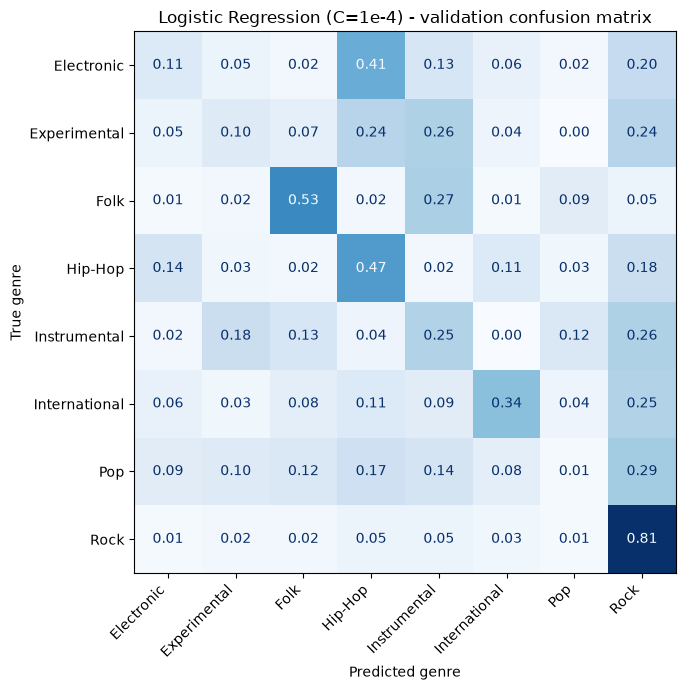

In [30]:
# --- Model 0: Baseline - Logistic Regression on flattened spectrograms ---
# Inputs from Section 3.5:
#   Xf_train (6393, 16384) | Xf_val | Xf_test   flattened pixels, already in [0, 1]
#   y_train / y_val / y_test                    integer genre_id
#
# C is the INVERSE of regularization strength, so small C = heavy constraint.
# With 16,384 features and 6,393 examples the default C=1.0 memorizes the training set;
# the sweep in the next cell picks C on the validation split.
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=5000, C=1e-4, n_jobs=-1, random_state=cfg.seed)
lr.fit(Xf_train, y_train)

val_pred = lr.predict(Xf_val)

record("Logistic Regression (C=1e-4)", lr, Xf_train, Xf_val, "flattened pixels")

print("\nVal accuracy:", accuracy_score(y_val, val_pred))
print("Val macro-F1:", f1_score(y_val, val_pred, average="macro"))
print(classification_report(y_val, val_pred,
                            target_names=[id_to_genre[i] for i in range(cfg.n_classes)],
                            zero_division=0))

plot_confusion(y_val, val_pred, "Logistic Regression (C=1e-4) - validation confusion matrix")

In [ ]:
# --- Model 1: Feed-Forward Neural Network on flattened spectrograms ---
# Inputs ready from Section 3.5:
#   Xf_train (6393, 16384) | Xf_val | Xf_test   flattened pixels
#   y_train / y_val / y_test                    integer genre_id
#
# TBD

# TODO: plot train vs val loss/accuracy

# When fitted, score it through the shared table:
# record("Feed-Forward NN", KerasModel, Xf_train, Xf_val, "2 hidden layers")
# plot_confusion(y_val, _labels(model, Xc_val), "<model name> - validation")

In [ ]:
# --- Model 2: Custom CNN on spectrograms ---
# Inputs ready from Section 3.5:
#   Xc_train (6393, 128, 128, 1) float32 in [0, 1]
#
# TBD

# TODO: plot train vs val loss/accuracy per epoch

# When fitted, score it through the shared table:
# record("Custom CNN", cnn, Xc_train, Xc_val, "4 conv blocks")
# plot_confusion(y_val, _labels(model, Xc_val), "<model name> - validation")

In [ ]:
# --- Model 3: ResNet-18 CNN on spectrograms ---
# Inputs ready from Section 3.5:
#   Xc_train (6393, 128, 128, 1) float32 in [0, 1]
#
# TBD

# TODO: plot train vs val loss/accuracy per epoch

# When fitted, score it through the shared table:
# record("ResNet-18", resnet, Xc_train, Xc_val, "ImageNet pretrained")
# plot_confusion(y_val, _labels(model, Xc_val), "<model name> - validation")

In [ ]:
# --- Model 4: CNN + LSTM on spectrograms ---
# Inputs ready from Section 3.5:
#   Xc_train (6393, 128, 128, 1) float32 in [0, 1]
#
# TBD

# TODO: plot train vs val loss/accuracy per epoch

# When fitted, score it through the shared table:
# record("CNN + LSTM", crnn, Xc_train, Xc_val, "CRNN, Choi et al. 2017")
# plot_confusion(y_val, _labels(model, Xc_val), "<model name> - validation")

---
## <span style="color: chocolate;">5 · Methodology 2: Tuning, Experiments, Model Selection</span>
Experiments: hyperparameter search, data augmentation. Baseline and CNN Model comparison and final model selection.

In [ ]:
# --- Experiments ---
# TODO: random search over LR / batch size / dropout etc.
# TODO: augmentation (time & frequency masking)
# TODO: test-time aggregation: single window vs averaged windows
# TODO: input comparison: 64x64 vs 128x128 vs 128x256

# --- Model comparison ---
comparison = (pd.DataFrame(model_results)
                .sort_values("val_f1", ascending=False)
                .reset_index(drop=True))
display(comparison)

# Persist for the report and for teammates
comparison.to_csv(TRACKED_DIR / "model_results.csv", index=False)
print("Saved ->", TRACKED_DIR / "model_results.csv")

# --- Model selection ---
# TODO: select argmax(val_f1); that model (and only that model) goes to Section 6.

---
## <span style="color: chocolate;">6 · Inference: Final Evaluation, Interpretation, Visualization</span>
Run the selected model on the held-out test split **once**. Explain the findings.

The confusion matrix can help show which genres overlap.

In [ ]:
# --- Final test evaluation ---
# TODO: accuracy, macro-F1, per-class precision/recall/F1, classification_report
# TODO: confusion matrix heatmap (normalized by true class, annotated, labeled axes)
# TODO: other analysis

In [ ]:
# --- SHAP interpretation ---
# TBD

---
## <span style="color: chocolate;">7 · Inference: Genre Classification UI</span>
User Interface that allows user to upload new audio file and get a genre prediction back which is displayed to the user. Reuse `mp3_to_melspec()` and `load_mel_tensor()`.

Full songs split into multiple windows. We can average the softmax, and show the per-window
predictions as well.

In [ ]:
# --- Input ---
# TODO: Colab file upload
# def prepare_new_audio(path, cfg):
#     # reuse mp3_to_melspec() -> split into windows -> load_mel_tensor() normalization
#     # -> stacked tensor
# NOTE: preprocessing must match training exactly (sr, n_fft, hop_length, n_mels,
#       fmax, top_db, and the same [-80,0] -> [0,1] mapping)

In [ ]:
# --- Predict & display ---
# def predict_genre(path, model, cfg, genre_mapping):
#     # TBD

# TODO: play audio back (IPython.display.Audio) + show its mel spectrogram
# TODO: sorted bar chart of all 8 class probabilities